# CSM ccPerturbSeq: QC Analysis
This notebook orchestrates the Q1, Q2, Q3, and Q4 QC analyses.

**Pipeline order:**
- **Q1**: Bulk Guide-Seq library QC (standalone — run separately via CLI)
- **Q2**: Recombination & background noise estimation (single-cell)
- **Q3**: KD efficacy + inferred source classification (single-cell)
- **Q4**: Fitness analysis (single-cell vs pre-lenti)

> Q1 is run independently via `python scripts/qc_q1_guideseq.py --config qc_config_guideseq.yaml`.
> This notebook covers Q2–Q4 which require single-cell data.

In [1]:
%load_ext autoreload
%autoreload 2

In [8]:
import os
import sys
import yaml
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

root_dir = "/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq"
os.chdir(root_dir)
sys.path.append(os.path.join(root_dir, "scripts"))

with open("qc_config.yaml") as f:
    cfg = yaml.safe_load(f)
recomb_cfg = cfg.get('recombination', {})
output_dir = os.path.join(root_dir, "output")
qc_out_dir = os.path.join(output_dir, "qc_analysis")
os.makedirs(qc_out_dir, exist_ok=True)
print(f"Set root to: {root_dir}")
print(f"Outputting QC to: {qc_out_dir}")

Set root to: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq
Outputting QC to: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis


## Load AnnData + Shared Resources

In [3]:
print("Loading AnnData...")
adata_path = os.path.join(output_dir, 'combined_adata.h5ad')
adata = sc.read_h5ad(adata_path)
print(f"Shape: {adata.shape}")

# Normalize early
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Load assignment / UMI tables
assign_path = os.path.join(output_dir, 'grna_assignment', 'grna_cell_assignment.csv')
umi_path = os.path.join(output_dir, 'grna_assignment', 'grna_umi_counts.csv')

assignment_df = pd.read_csv(assign_path)
umi_df = pd.read_csv(umi_path)
print(f"Assignment: {len(assignment_df):,} rows")
print(f"UMI table:  {len(umi_df):,} rows")

valid_bcs = set(adata.obs.index)

Loading AnnData...
Shape: (37086, 38606)
Assignment: 45,814 rows
UMI table:  1,371,054 rows


---
# Q2: Recombination & Background Noise Estimation

Estimate ambient guide noise, guide UMI distributions, recombination model parameters,
and run a UMI threshold sensitivity sweep.

## Q2a: Background Noise Estimation


  --- Part A.1: Background Noise Estimation (perfect_singlet, total_umi) ---
    Found 19,673 perfect singlets for noise 
    Global Off-Target Noise Distribution (per cell):
      Mean:            9.59
      Median:          8.00
      95th Percentile: 25.00

  --- Part A.1: Background Noise Estimation (perfect_singlet, n_guides) ---
    Found 19,673 perfect singlets for noise 
    Global Off-Target Noise Distribution (per cell):
      Mean:            7.05
      Median:          6.00
      95th Percentile: 15.00

  --- Part A.1: Background Noise Estimation (perfect_singlet, mean_umi) ---
    Found 19,673 perfect singlets for noise 
    Global Off-Target Noise Distribution (per cell):
      Mean:            1.04
      Median:          1.00
      95th Percentile: 1.25


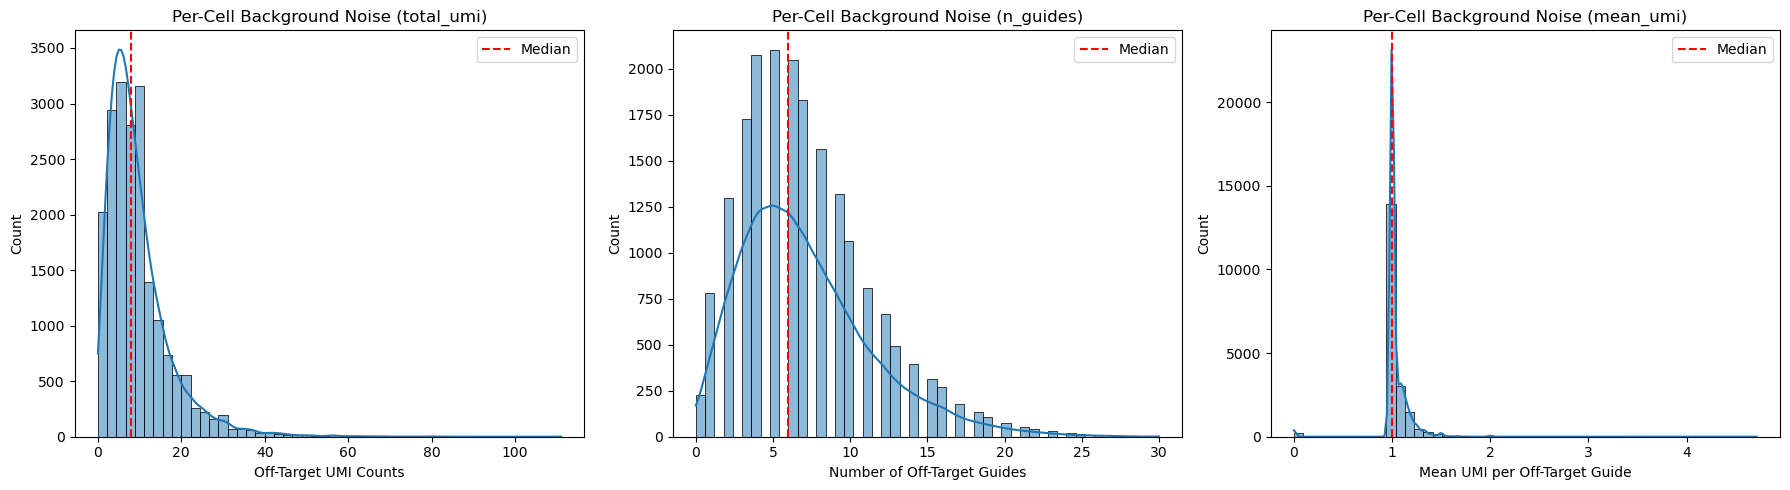

In [4]:
import scripts.qc_q2_recombination as q2

# --- Perfect singlet noise ---
per_cell_noise = q2.estimate_background_noise(adata, assignment_df, umi_df)
per_cell_noise_nguide = q2.estimate_background_noise(adata, assignment_df, umi_df, metric="n_guides")
per_cell_noise_mean = q2.estimate_background_noise(adata, assignment_df, umi_df, metric="mean_umi")

plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
sns.histplot(per_cell_noise, bins=50, kde=True)
plt.xlabel('Off-Target UMI Counts')
plt.title('Per-Cell Background Noise (total_umi)')
plt.axvline(per_cell_noise.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,2)
sns.histplot(per_cell_noise_nguide, bins=50, kde=True)
plt.xlabel('Number of Off-Target Guides')
plt.title('Per-Cell Background Noise (n_guides)')
plt.axvline(per_cell_noise_nguide.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,3)
sns.histplot(per_cell_noise_mean, bins=50, kde=True)
plt.xlabel('Mean UMI per Off-Target Guide')
plt.title('Per-Cell Background Noise (mean_umi)')
plt.axvline(per_cell_noise_mean.median(), color='red', linestyle='--', label='Median')
plt.legend()
plt.tight_layout()

%matplotlib inline
plt.show()


  --- Part A.1: Background Noise Estimation (unassigned, total_umi) ---
    Found 5,824 unassigned cells for noise estimation.
    Global Off-Target Noise Distribution (per cell):
      Mean:            5.90
      Median:          5.00
      95th Percentile: 13.00

  --- Part A.1: Background Noise Estimation (unassigned, n_guides) ---
    Found 5,824 unassigned cells for noise estimation.
    Global Off-Target Noise Distribution (per cell):
      Mean:            4.29
      Median:          4.00
      95th Percentile: 9.00

  --- Part A.1: Background Noise Estimation (unassigned, mean_umi) ---
    Found 5,824 unassigned cells for noise estimation.
    Global Off-Target Noise Distribution (per cell):
      Mean:            1.20
      Median:          1.00
      95th Percentile: 2.00


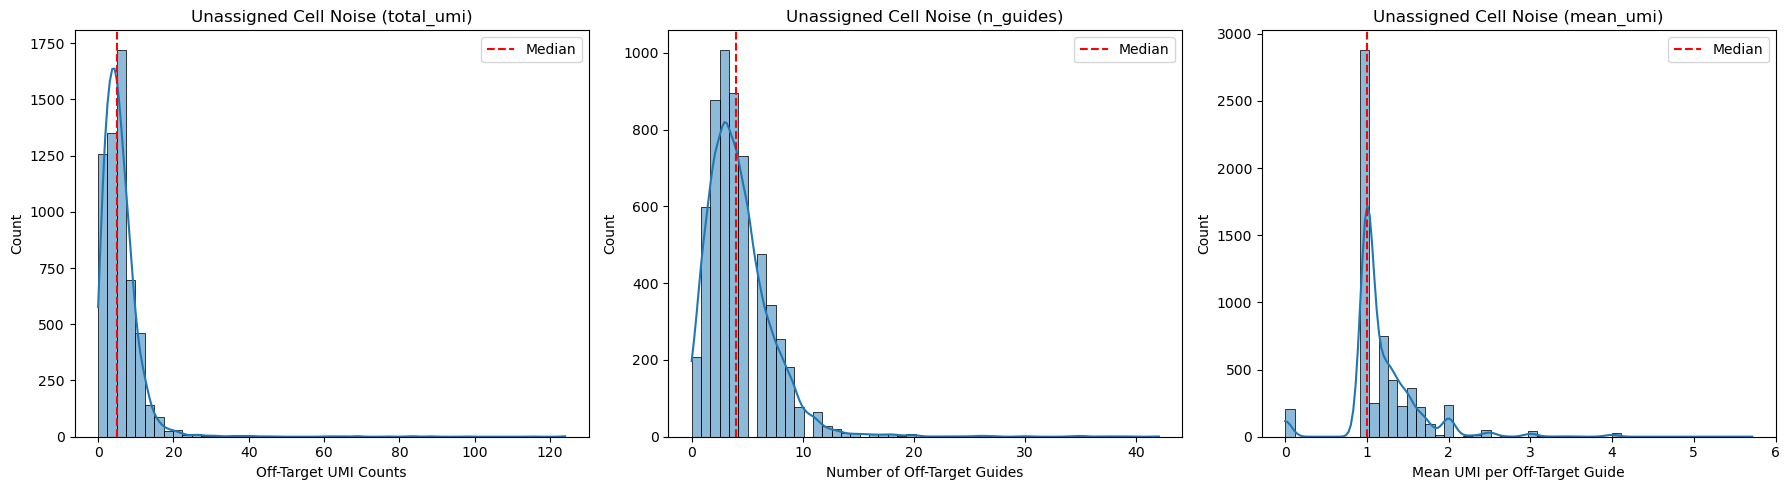

In [5]:
# --- Unassigned cell noise ---
per_cell_noise_unassigned = q2.estimate_background_noise(adata, assignment_df, umi_df, cell_category='unassigned')
per_cell_noise_nguide_unassigned = q2.estimate_background_noise(adata, assignment_df, umi_df, cell_category='unassigned', metric="n_guides")
per_cell_noise_mean_unassigned = q2.estimate_background_noise(adata, assignment_df, umi_df, cell_category='unassigned', metric="mean_umi")

plt.figure(figsize=(18,5))
plt.subplot(1,3,1)
sns.histplot(per_cell_noise_unassigned, bins=50, kde=True)
plt.xlabel('Off-Target UMI Counts')
plt.title('Unassigned Cell Noise (total_umi)')
plt.axvline(per_cell_noise_unassigned.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,2)
sns.histplot(per_cell_noise_nguide_unassigned, bins=50, kde=True)
plt.xlabel('Number of Off-Target Guides')
plt.title('Unassigned Cell Noise (n_guides)')
plt.axvline(per_cell_noise_nguide_unassigned.median(), color='red', linestyle='--', label='Median')
plt.legend()

plt.subplot(1,3,3)
sns.histplot(per_cell_noise_mean_unassigned, bins=50, kde=True)
plt.xlabel('Mean UMI per Off-Target Guide')
plt.title('Unassigned Cell Noise (mean_umi)')
plt.axvline(per_cell_noise_mean_unassigned.median(), color='red', linestyle='--', label='Median')
plt.legend()
plt.tight_layout()
plt.show()

## Q2a (optional): Guide UMI Distributions

Estimate per-guide mean/std of log10(UMI count) from perfect singlets.
These can feed a GMM-based guide assignment refinement.

In [6]:
guide_dist_df = q2.compute_guide_umi_distributions(assignment_df, umi_df)
display(guide_dist_df.head(20))

# Save
guide_dist_df.to_csv(os.path.join(qc_out_dir, 'q2_guide_umi_distributions.csv'), index=False)
print(f"Saved guide UMI distributions: {len(guide_dist_df)} guides")


  --- Part A.2: Guide UMI Distributions ---
    Using 23,575 perfect singlets.
    Computed UMI distributions for 62 unique guides.


,guide_name,mean_log10_umi,std_log10_umi,n_cells
0,ADAMTS7_A_1,1.000089,0.464244,880
1,ADAMTS7_A_2,0.949242,0.446698,1177
2,ADAMTS7_A_3,0.952834,0.470808,967
3,CCM2_A_1,0.789340,0.407217,1631
4,CCM2_A_2,0.174466,0.233793,435
5,CCM2_A_3,0.631130,0.357477,1378
6,CEBPB_B_1,1.425430,0.462207,872
7,CEBPB_B_2,1.521144,0.503276,1127
8,CEBPB_B_3,1.259395,0.400811,585
9,FDX1_A_1,0.223887,0.249111,333


Saved guide UMI distributions: 62 guides


## Q2b: gRNA-iBAR Decoupling QC

Subcategorized Decoupling Analysis for each guide unit (grna_name, ibar_seq):
* correct: if unit found in reference
* wrong_target (gRNA resolved, iBAR exists but belongs to a different target)
* ibar_missing (gRNA resolved, iBAR failed, possibly due to sequencing errors)
* novel_ibar (iBAR sequence not in the design library at all)

In [12]:
import scripts.qc_q2_recombination as q2
# Run the decoupling analysis
ref_path = cfg['paths']['grna_reference']
ref_df = pd.read_csv(ref_path)

# get umi threshold from config
umi_threshold = recomb_cfg.get('umi_thresholds', 1)  # default to 1 if not set

print(f"Using UMI threshold: {umi_threshold}")

# Note: we pass valid_bcs so it only considers GEX-positive cells
decouple_res = q2.analyze_grna_ibar_pairing(
    umi_df, 
    ref_df, 
    out_dir=qc_out_dir, 
    valid_bcs=valid_bcs,
	umi_thresholds=umi_threshold,
	save_decoupled=False,
	return_df=False
)
display(decouple_res['summary_df']) 

Using UMI threshold: [1, 2, 3, 4, 5, 8, 10]

  Part B.2: gRNA-iBAR Pairing QC (Decoupling)
    Total UMI entries (with gRNA match, >= 1 UMIs): 431,825
    Cell-level decoupling rate at >= 1 UMIs:         0.2874 (10,599/36,879 cells)
    Tested 7 UMI thresholds. Use plot_decoupling_vs_umi_threshold() to visualize.


,umi_threshold,total,correct,decoupled_total,wrong_target,ibar_missing,novel_ibar,pct_correct,pct_decoupled,n_cells,n_cells_decoupled,cell_decoupling_rate
0,1,431825,417033,14792,6749,8043,0,96.574538,3.425462,36879,10599,0.287399
1,2,84876,82064,2812,229,2583,0,96.686932,3.313068,33999,2638,0.077591
2,3,64182,62736,1446,146,1300,0,97.747032,2.252968,32588,1365,0.041887
3,4,57863,56979,884,113,771,0,98.472253,1.527747,31592,847,0.026811
4,5,53759,53161,598,99,499,0,98.887628,1.112372,30657,574,0.018723
5,8,45203,44925,278,77,201,0,99.384997,0.615003,28189,269,0.009543
6,10,40819,40623,196,70,126,0,99.519831,0.480169,26535,192,0.007236


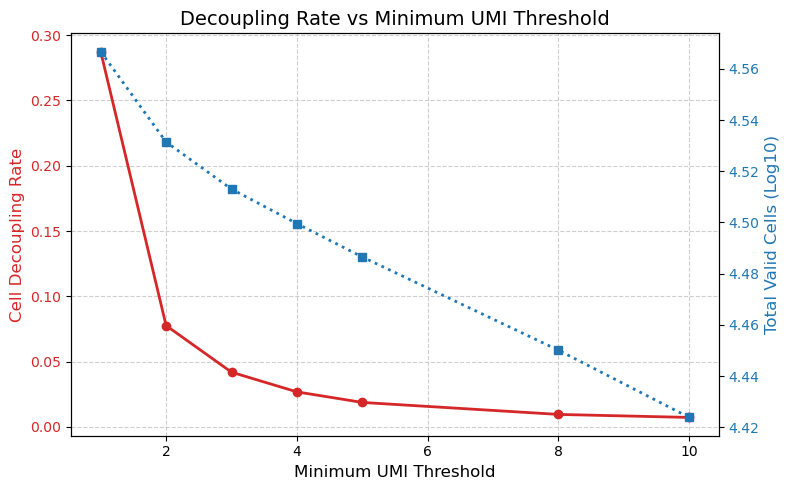

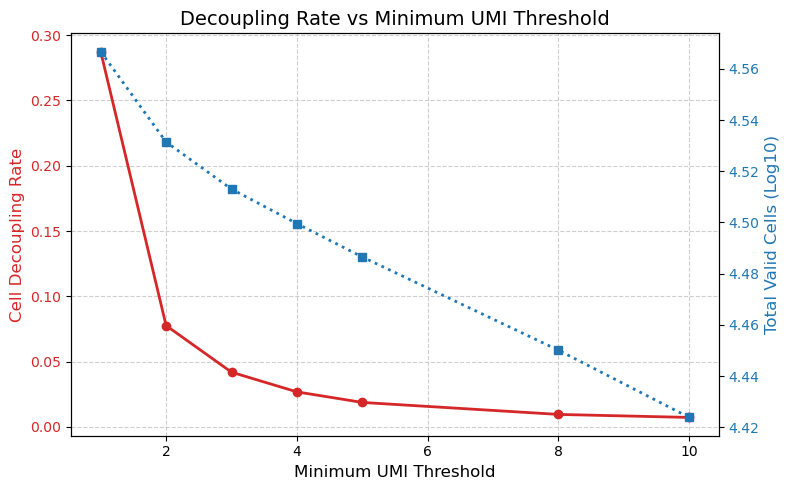

In [14]:
q2.plot_decoupling_vs_umi_threshold(decouple_res['summary_df'])

In [26]:
umi_df.query('bc_wells == "0_22_87_26" & ibar_seq_corrected == "AGGTGCA"')

,bc_wells,grna_name,ibar_seq_corrected,target_gene,umi_count,umi_count_raw,read_count,sublibrary,sample_name,position,stem_variant,pair_id,target_combo,target_version,gi_pair,gi_version,ibar_seq
1082,0_22_87_26,FDX1_A_2,AGGTGCA,FDX1,87,117,2876,C1,Control,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
cfg['paths']['grna_reference']
# Load gRNA-iBAR UMI counts for decoupling analysis
grna_ibar_path = os.path.join(output_dir, 'grna_assignment', 'grna_ibar_umi_counts.csv')
if os.path.exists(grna_ibar_path):
    grna_ibar_df = pd.read_csv(grna_ibar_path)
    
    # Load reference table
    ref_path = cfg['paths'].get('grna_reference', '')
    if os.path.exists(ref_path):
        ref_df = pd.read_csv(ref_path, sep='\t')
        pairing_stats = q2.analyze_grna_ibar_pairing(grna_ibar_df, ref_df, qc_out_dir)
        display(pd.DataFrame([pairing_stats]))
    else:
        print(f"Reference table not found: {ref_path}")
else:
    print("gRNA-iBAR UMI counts not found. Skipping decoupling QC.")

gRNA-iBAR UMI counts not found. Skipping decoupling QC.


## Q2b: Recombination Model (MLE)

In [ ]:

moi = recomb_cfg.get('moi', 0.3)
doublet_rate = recomb_cfg.get('doublet_rate', 0.03)
print(f"Using fixed parameters: MOI={moi}, Doublet Rate={doublet_rate}")

Using fixed parameters: MOI=0.089, Doublet Rate=0.03


## Q2c: UMI Threshold Sweep

Re-run guide assignment at varying UMI thresholds and fit recombination parameters at each.

In [ ]:
# --- Threshold sweep ---
thresholds = [1, 2, 3, 4, 5, 8, 10]
sweep_results = q2.sweep_umi_threshold(
    deduped_df = umi_df, 
	ref_df = 
)
sweep_umi_threshold(umi_df, ref_df, valid_bcs, out_dir, recomb_cfg)

# Display summary
sweep_df = pd.DataFrame(sweep_results)
display(sweep_df)

TypeError: sweep_umi_threshold() got an unexpected keyword argument 'moi'

---
# Q3: KD Efficacy + Inferred Source Classification

Assess per-guide knockdown efficacy and classify inferred singlets.

## Q3 Setup — Classify Cells

In [8]:
import qc_q3_kd_efficacy as q3

# Full classification overview
cell_sets_full = q3.classify_cells_full(adata)

# Perfect singlets and inferred singlets
perfect_df = cell_sets_full['perfect_singlet']
inferred_df = cell_sets_full['inferred_singlet']
print(f"\nPerfect singlets: {len(perfect_df):,}")
print(f"Inferred singlets: {len(inferred_df):,}")

# ctrl_ctrl reference: ALWAYS from perfect singlets
ctrl_bcs_per_sample = {}
for sn in ['Control', 'Treatment']:
    ps = perfect_df[perfect_df['sample'] == sn]
    ctrl_bcs_per_sample[sn] = q3.get_ctrl_ctrl_cells(ps).index.tolist()
    print(f"  ctrl_ctrl ref ({sn}): {len(ctrl_bcs_per_sample[sn]):,}")


  Comprehensive Cell Classification:
    Category                          Count  % of Total
    ────────────────────────────────────────────────────
    perfect_singlet                  19,673       53.0%
    inferred_singlet                  5,794       15.6%
    perfect_multiplet                 1,826        4.9%
    inferred_multi_mismatch           1,834        4.9%
    inferred_multi_single_pos         2,135        5.8%
    unassigned                        5,824       15.7%
    ────────────────────────────────────────────────────
    TOTAL                            37,086      100.0%

Perfect singlets: 19,673
Inferred singlets: 5,794
  ctrl_ctrl ref (Control): 985
  ctrl_ctrl ref (Treatment): 1,439


---
## Q3a: Perfect Singlet — Gold-Standard Guide Efficacy

Establish baseline KD efficacy using perfect singlets (both positions detected).
- **Test 1 (gRNA_ctrl)**: Guides paired with ctrl partner (X_ctrl / ctrl_X)
- **Test 2 (gRNA_nonctrl)**: Guides paired with non-ctrl partner (X_Y)

Each test produces a heatmap with 4 rows: `gRNA_1, gRNA_2, gRNA_3, all`.

In [14]:
# === Q3a Test 1: Perfect singlet — gRNA_ctrl ===
# Per-guide (group_by_gene=False) + pooled (group_by_gene=True)

all_q3a_ctrl = []
for sample_name in ['Control', 'Treatment']:
    sample_cells = perfect_df[perfect_df['sample'] == sample_name]
    ctrl_bcs = ctrl_bcs_per_sample[sample_name]
    
    # Individual guides
    guide_groups_indiv = q3.get_grna_ctrl_cells(sample_cells, group_by_gene=False)
    mdf_indiv = q3.compute_kd_metrics(adata, guide_groups_indiv, ctrl_bcs, sample_name, min_cells=5)
    
    # Pooled per target gene
    guide_groups_pooled = q3.get_grna_ctrl_cells(sample_cells, group_by_gene=True)
    mdf_pooled = q3.compute_kd_metrics(adata, guide_groups_pooled, ctrl_bcs, sample_name, min_cells=5)
    
    if not mdf_indiv.empty:
        mdf_indiv = mdf_indiv.copy()
        mdf_indiv['guide_name'] = mdf_indiv['guide_name'].apply(
            lambda x: f"gRNA_{x.rsplit('_', 1)[-1]}" if x.rsplit('_', 1)[-1].isdigit() else x
        )
        all_q3a_ctrl.append(mdf_indiv)
    
    if not mdf_pooled.empty:
        mdf_pooled = mdf_pooled.copy()
        mdf_pooled['guide_name'] = 'all'
        all_q3a_ctrl.append(mdf_pooled)

q3a_ctrl = pd.concat(all_q3a_ctrl, ignore_index=True) if all_q3a_ctrl else pd.DataFrame()
q3a_ctrl['test_mode'] = 'q3a_ctrl'

q3.plot_heatmap(q3a_ctrl, os.path.join(qc_out_dir, 'q3a_heatmap_ctrl.png'),
                title_suffix=' (Q3a: gRNA × ctrl)', show_pval=True)

print(f"Q3a ctrl results: {len(q3a_ctrl)} rows")
display(q3a_ctrl)

    Saved heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_ctrl_control.png
    Saved heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_ctrl_treatment.png
Q3a ctrl results: 96 rows


,guide_name,target_gene,position,target_combo,sample,n_kd_cells,n_ctrl_cells,cpm_kd,cpm_ctrl,pct_nonzero_kd,pct_nonzero_ctrl,log2FC,pvalue,cohens_d,note,test_mode
0,gRNA_3,ZEB2_hg38,pos1,ZEB2_ctrl,Control,37,985,132.642197,199.109604,56.756757,64.974619,-0.414359,5.700832e-02,-0.297183,,q3a_ctrl
1,gRNA_2,ZEB2_hg38,pos1,ZEB2_ctrl,Control,62,985,178.377533,199.109604,61.290323,64.974619,-0.084073,7.398088e-01,-0.067230,,q3a_ctrl
2,gRNA_1,ZEB2_hg38,pos1,ZEB2_ctrl,Control,109,985,162.204330,199.109604,60.550459,64.974619,-0.183767,1.722630e-01,-0.142656,,q3a_ctrl
3,gRNA_3,TLNRD1_hg38,pos1,TLNRD1_ctrl,Control,75,985,16.097279,34.119026,12.000000,19.492386,-0.861621,8.781337e-02,-0.221380,,q3a_ctrl
4,gRNA_1,TLNRD1_hg38,pos1,TLNRD1_ctrl,Control,60,985,14.240413,34.119026,11.666667,19.492386,-0.931633,1.074857e-01,-0.233894,,q3a_ctrl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,all,CEBPB_hg38,pos2,CEBPB_ctrl,Treatment,171,1439,5.621154,4.493237,1.754386,2.154274,-0.077210,7.310632e-01,-0.010555,,q3a_ctrl
92,all,ZEB2_hg38,pos1,ZEB2_ctrl,Treatment,308,1439,297.052216,312.124115,70.454545,69.006254,-0.004287,8.814740e-01,-0.003978,,q3a_ctrl
93,all,ADAMTS7_hg38,pos1,ADAMTS7_ctrl,Treatment,202,1439,0.955510,40.716618,0.495050,18.137596,-3.785234,1.822476e-10,-0.460844,,q3a_ctrl
94,all,JUN_hg38,pos2,JUN_ctrl,Treatment,186,1439,77.194412,120.379082,26.344086,39.680334,-0.604985,4.304565e-04,-0.265765,,q3a_ctrl


In [15]:
# === Q3a Test 2: Perfect singlet — gRNA_nonctrl ===

all_q3a_nonctrl = []
for sample_name in ['Control', 'Treatment']:
    sample_cells = perfect_df[perfect_df['sample'] == sample_name]
    ctrl_bcs = ctrl_bcs_per_sample[sample_name]
    
    guide_groups_indiv = q3.get_grna_any_cells(sample_cells, group_by_gene=False)
    mdf_indiv = q3.compute_kd_metrics(adata, guide_groups_indiv, ctrl_bcs, sample_name, min_cells=5)
    
    guide_groups_pooled = q3.get_grna_any_cells(sample_cells, group_by_gene=True)
    mdf_pooled = q3.compute_kd_metrics(adata, guide_groups_pooled, ctrl_bcs, sample_name, min_cells=5)
    
    if not mdf_indiv.empty:
        mdf_indiv = mdf_indiv.copy()
        mdf_indiv['guide_name'] = mdf_indiv['guide_name'].apply(
            lambda x: f"gRNA_{x.rsplit('_', 1)[-1]}" if x.rsplit('_', 1)[-1].isdigit() else x
        )
        all_q3a_nonctrl.append(mdf_indiv)
    
    if not mdf_pooled.empty:
        mdf_pooled = mdf_pooled.copy()
        mdf_pooled['guide_name'] = 'all'
        all_q3a_nonctrl.append(mdf_pooled)

q3a_nonctrl = pd.concat(all_q3a_nonctrl, ignore_index=True) if all_q3a_nonctrl else pd.DataFrame()
q3a_nonctrl['test_mode'] = 'q3a_nonctrl'

q3.plot_heatmap(q3a_nonctrl, os.path.join(qc_out_dir, 'q3a_heatmap_nonctrl.png'),
                title_suffix=' (Q3a: gRNA × nonctrl)', show_pval=True)

print(f"Q3a nonctrl results: {len(q3a_nonctrl)} rows")
display(q3a_nonctrl)

    Saved heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_nonctrl_control.png
    Saved heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3a_heatmap_nonctrl_treatment.png
Q3a nonctrl results: 110 rows


,guide_name,target_gene,position,target_combo,sample,n_kd_cells,n_ctrl_cells,cpm_kd,cpm_ctrl,pct_nonzero_kd,pct_nonzero_ctrl,log2FC,pvalue,cohens_d,note,test_mode
0,gRNA_2,TLNRD1_hg38,pos1,TLNRD1_nonctrl,Control,350,985,11.912015,34.119026,6.000000,19.492386,-1.440000,5.942859e-09,-0.331822,,q3a_nonctrl
1,gRNA_1,TLNRD1_hg38,pos1,TLNRD1_nonctrl,Control,238,985,25.974886,34.119026,13.025210,19.492386,-0.407553,3.574505e-02,-0.120878,,q3a_nonctrl
2,gRNA_3,TLNRD1_hg38,pos1,TLNRD1_nonctrl,Control,401,985,22.508921,34.119026,13.216958,19.492386,-0.529657,6.104681e-03,-0.155472,,q3a_nonctrl
3,gRNA_3,KLF4_hg38,pos2,KLF4_nonctrl,Control,247,985,0.000000,5.411246,0.000000,4.060914,-2.125156,1.292798e-03,-0.223443,,q3a_nonctrl
4,gRNA_1,KLF4_hg38,pos2,KLF4_nonctrl,Control,281,985,0.000000,5.411246,0.000000,4.060914,-2.125156,6.025674e-04,-0.226510,,q3a_nonctrl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,all,ZEB2_hg38,pos1,ZEB2_nonctrl,Treatment,1273,1439,289.272064,312.124115,67.478397,69.006254,-0.064079,1.006647e-01,-0.058308,,q3a_nonctrl
106,all,MEF2C_hg38,pos2,MEF2C_nonctrl,Treatment,1061,1439,15.014890,48.983299,6.974552,19.388464,-1.467754,6.404308e-19,-0.362347,,q3a_nonctrl
107,all,LAMB2_hg38,pos1,LAMB2_nonctrl,Treatment,970,1439,9.760307,97.730225,4.536082,37.109104,-3.001211,1.119519e-75,-0.797886,,q3a_nonctrl
108,all,CEBPB_hg38,pos2,CEBPB_nonctrl,Treatment,1081,1439,1.341125,4.493237,0.462535,2.154274,-1.053149,4.132145e-04,-0.126472,,q3a_nonctrl


In [16]:
# Save combined Q3a results
q3a_all = pd.concat([q3a_ctrl, q3a_nonctrl], ignore_index=True)
q3a_all.to_csv(os.path.join(qc_out_dir, 'q3a_guide_efficacy.csv'), index=False)
print(f"Saved Q3a: {len(q3a_all)} rows")

Saved Q3a: 206 rows


---
## Q3b: Validation — Inferred Singlets + Perfect All

Validate guide efficacy in lower-power settings. All tests use **gene-pooled** groups.

Three test groups:
1. **`perfect_all`**: ALL combos (ctrl + nonctrl) in perfect singlets → maximum power baseline
2. **`detected_in_inferred`**: The guide at the DETECTED position in inferred singlets
3. **`inferred_in_inferred`**: The guide at the INFERRED position in inferred singlets

> **Note**: Q3b `perfect_all` uses ALL combos (via `get_grna_all_cells`), unlike Q3a which uses only gRNA_ctrl.

When gRNA_ctrl has < 5 cells for a target, we fall back to gRNA_all and notify.

In [17]:
# === Q3b: Validation ===
MIN_CELLS_Q3B = 5

q3b_tests = [
    ('perfect_all',         perfect_df,  q3.get_grna_all_cells,        'Perfect singlet (all combos)'),
    ('detected_in_inferred', inferred_df, q3.get_detected_guide_cells, 'Inferred singlet (detected guide)'),
    ('inferred_in_inferred', inferred_df, q3.get_inferred_guide_cells, 'Inferred singlet (inferred guide)'),
]

all_q3b = []
for mode_name, cell_df, group_fn, description in q3b_tests:
    print(f"\n{'='*60}")
    print(f"  Q3b: {description}")
    print(f"{'='*60}")
    
    for sample_name in ['Control', 'Treatment']:
        sample_cells = cell_df[cell_df['sample'] == sample_name]
        ctrl_bcs = ctrl_bcs_per_sample[sample_name]
        
        if len(sample_cells) == 0:
            print(f"  {sample_name}: no cells, skipping")
            continue
        
        guide_groups = group_fn(sample_cells, group_by_gene=True)
        
        # Check for low-n targets and fall back to gRNA_all
        fallback_targets = []
        for g in guide_groups:
            if g['n_cells'] < MIN_CELLS_Q3B:
                fallback_targets.append(g['target_gene'])
        
        if fallback_targets and mode_name != 'perfect_all':
            print(f"  ⚠ {sample_name}: {len(fallback_targets)} target(s) have <{MIN_CELLS_Q3B} cells "
                  f"in {mode_name}: {fallback_targets}")
            print(f"    → Falling back to gRNA_all for these targets")
            
            all_groups = q3.get_grna_all_cells(sample_cells, group_by_gene=True)
            all_groups_by_gene = {g['target_gene']: g for g in all_groups}
            
            new_groups = []
            for g in guide_groups:
                if g['target_gene'] in fallback_targets and g['target_gene'] in all_groups_by_gene:
                    fb = all_groups_by_gene[g['target_gene']].copy()
                    fb['guide_name'] = f"{g['target_gene']}_all (fallback)"
                    new_groups.append(fb)
                else:
                    new_groups.append(g)
            guide_groups = new_groups
        
        print(f"  {sample_name}: {len(sample_cells):,} cells, "
              f"{len(ctrl_bcs):,} ctrl (shared), {len(guide_groups)} gene groups")
        
        if not guide_groups:
            continue
        
        mdf = q3.compute_kd_metrics(adata, guide_groups, ctrl_bcs, sample_name, min_cells=MIN_CELLS_Q3B)
        if not mdf.empty:
            mdf['test_mode'] = mode_name
            all_q3b.append(mdf)

q3b_results = pd.concat(all_q3b, ignore_index=True) if all_q3b else pd.DataFrame()

q3b_results.to_csv(os.path.join(qc_out_dir, 'q3b_validation.csv'), index=False)
print(f"\nQ3b total: {len(q3b_results)} rows")
display(q3b_results)


  Q3b: Perfect singlet (all combos)
  Control: 7,922 cells, 985 ctrl (shared), 13 gene groups
  Treatment: 11,751 cells, 1,439 ctrl (shared), 13 gene groups

  Q3b: Inferred singlet (detected guide)
  Control: 2,170 cells, 985 ctrl (shared), 13 gene groups
  Treatment: 3,624 cells, 1,439 ctrl (shared), 13 gene groups

  Q3b: Inferred singlet (inferred guide)
  Control: 2,170 cells, 985 ctrl (shared), 13 gene groups
  Treatment: 3,624 cells, 1,439 ctrl (shared), 13 gene groups

Q3b total: 78 rows


,guide_name,target_gene,position,target_combo,sample,n_kd_cells,n_ctrl_cells,cpm_kd,cpm_ctrl,pct_nonzero_kd,pct_nonzero_ctrl,log2FC,pvalue,cohens_d,note,test_mode
0,TLNRD1_all,TLNRD1_hg38,pos1,TLNRD1_all,Control,1266,985,18.955135,34.119026,10.584518,19.492386,-0.781099,5.550348e-09,-0.228644,,perfect_all
1,KLF4_all,KLF4_hg38,pos2,KLF4_all,Control,883,985,0.150100,5.411246,0.113250,4.060914,-1.993474,6.185110e-09,-0.264041,,perfect_all
2,ZEB2_all,ZEB2_hg38,pos1,ZEB2_all,Control,1088,985,167.062241,199.109604,60.661765,64.974619,-0.171216,2.409668e-03,-0.135855,,perfect_all
3,CEBPB_all,CEBPB_hg38,pos2,CEBPB_all,Control,836,985,1.021773,3.215355,0.837321,2.131980,-0.820352,2.475621e-02,-0.111421,,perfect_all
4,CCM2_all,CCM2_hg38,pos1,CCM2_all,Control,1222,985,50.774395,80.114128,25.941080,38.680203,-0.602999,8.732008e-11,-0.275377,,perfect_all
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,JUN_all_inferred,JUN_hg38,pos2,JUN_inferred,Treatment,90,1439,94.110703,120.379082,31.111111,39.680334,-0.333448,1.254446e-01,-0.158482,,inferred_in_inferred
74,MEF2C_all_inferred,MEF2C_hg38,pos2,MEF2C_inferred,Treatment,79,1439,52.572018,48.983299,21.518987,19.388464,0.091380,6.881554e-01,0.031492,,inferred_in_inferred
75,KLF4_all_inferred,KLF4_hg38,pos2,KLF4_inferred,Treatment,32,1439,8.750880,11.671645,6.250000,5.767894,-0.152466,9.431803e-01,-0.028019,,inferred_in_inferred
76,NFKB1_all_inferred,NFKB1_hg38,pos2,NFKB1_inferred,Treatment,118,1439,452.613617,523.300354,83.050847,84.850591,-0.110782,8.330189e-02,-0.145018,,inferred_in_inferred


In [18]:
# --- Q3b: Combined heatmap per sample ---
q3.plot_q1b_heatmap(
    q3b_results,
    os.path.join(qc_out_dir, 'q3b_heatmap_combined.png'),
    title_suffix='',
    show_pval=True
)

    Saved heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3b_heatmap_combined_control.png
    Saved heatmap: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3b_heatmap_combined_treatment.png


In [19]:
# --- Q3b: 3-color volcano comparison ---
PVAL_CAP = 10
q3.plot_volcano_comparison(
    q3b_results,
    os.path.join(qc_out_dir, 'q3b_volcano_comparison.png'),
    max_neg_log10p=PVAL_CAP
)

    Saved comparison volcano: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3b_volcano_comparison_control.png
    Saved comparison volcano: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3b_volcano_comparison_treatment.png


---
### Custom Combo KD Analysis

Use `compute_custom_combo_de` for multi-combo × multi-gene analyses, or `compare_expression` for quick pairwise comparisons.

In [12]:
# --- Custom Combo KD Analysis ---

target_combos = ['CCM2_ctrl', 'TLNRD1_ctrl', 'CCM2_TLNRD1', 'CCM2_MAPK7']
readout_genes = ['CCM2', 'TLNRD1', 'MAPK7', 'KLF2', 'KLF4']

# Use perfect singlets
singlets = adata.obs[
    (adata.obs['combo_type'] == 'singlet') & 
    (adata.obs['detection_status'] == 'complete')
]

all_gene_dfs = []
all_guide_dfs = []

for sample_name in ['Control', 'Treatment']:
    sample_cells = singlets[singlets['sample'] == sample_name]
    ctrl_bcs = sample_cells[sample_cells['target_combo'] == 'ctrl_ctrl'].index.tolist()
    print(f"\n  {sample_name}: {len(sample_cells):,} singlets, {len(ctrl_bcs):,} ctrl_ctrl")
    
    gene_df, guide_df = q3.compute_custom_combo_de(
        adata, sample_cells, target_combos, readout_genes, ctrl_bcs, sample_name
    )
    all_gene_dfs.append(gene_df)
    all_guide_dfs.append(guide_df)

gene_results = pd.concat(all_gene_dfs, ignore_index=True)
guide_results = pd.concat(all_guide_dfs, ignore_index=True)

gene_results.to_csv(os.path.join(qc_out_dir, 'q3_custom_combo_gene_level.csv'), index=False)
guide_results.to_csv(os.path.join(qc_out_dir, 'q3_custom_combo_guide_level.csv'), index=False)

# preserve the order of target_combos and readout_genes for the heatmap
guide_results['target_combo'] = pd.Categorical(guide_results['target_combo'], categories=target_combos, ordered=True)
guide_results['readout_gene'] = pd.Categorical(guide_results['readout_gene'], categories=readout_genes, ordered=True)

q3.plot_custom_combo_heatmap(
    gene_results, 
    os.path.join(qc_out_dir, 'q3_custom_combo_heatmap.png'),
    title='Custom Combo KD (Gene-Level)',
    show=True
)

display(gene_results)


  Control: 7,922 singlets, 985 ctrl_ctrl

  Treatment: 11,751 singlets, 1,439 ctrl_ctrl


/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:14: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  Reference: ctrl_ctrl singlet cells (both positions targeting nothing).
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:15: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:16: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  For X_ctrl cells → test KD of gene X (pos1 guide).
/home/unix

    Saved: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3_custom_combo_heatmap_control.png


/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:14: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  Reference: ctrl_ctrl singlet cells (both positions targeting nothing).
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:15: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:16: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  For X_ctrl cells → test KD of gene X (pos1 guide).
/home/unix

    Saved: /home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/output/qc_analysis/q3_custom_combo_heatmap_treatment.png


,target_combo,readout_gene,sample,level,guide_pair,n_kd,n_ctrl,cpm_kd,cpm_ctrl,log2FC,pvalue,cohens_d
0,CCM2_ctrl,CCM2,Control,gene_combo,all,84,985,72.380066,80.114128,-0.072817,0.850738,-0.036836
1,CCM2_ctrl,TLNRD1,Control,gene_combo,all,84,985,43.468956,34.119026,0.276132,0.444594,0.100974
2,CCM2_ctrl,MAPK7,Control,gene_combo,all,84,985,16.742123,9.588488,0.693928,0.145790,0.177312
3,CCM2_ctrl,KLF2,Control,gene_combo,all,84,985,66.636002,39.864086,0.640671,0.016184,0.289090
4,CCM2_ctrl,KLF4,Control,gene_combo,all,84,985,11.010299,5.411246,0.763525,0.178612,0.173720
5,TLNRD1_ctrl,CCM2,Control,gene_combo,all,164,985,69.769188,80.114128,-0.151471,0.382178,-0.074758
6,TLNRD1_ctrl,TLNRD1,Control,gene_combo,all,164,985,12.571467,34.119026,-1.143959,0.001740,-0.277210
7,TLNRD1_ctrl,MAPK7,Control,gene_combo,all,164,985,10.551052,9.588488,0.233080,0.261444,0.051734
8,TLNRD1_ctrl,KLF2,Control,gene_combo,all,164,985,44.929317,39.864086,0.150856,0.458306,0.057727
9,TLNRD1_ctrl,KLF4,Control,gene_combo,all,164,985,8.734317,5.411246,0.522122,0.236474,0.108403


### `compare_expression` — General-Purpose Comparison Utility

For quick, flexible comparisons between any two cell groups. Supports:
- `plot_type='heatmap'`, `'violin'`, or `'both'`
- `show_pval=True` for p-value annotation (Mann-Whitney U)

In [7]:
obs = adata.obs
singlet_mask = (obs['combo_type'] == 'singlet') & (obs['detection_status'] == 'complete')
target_combo = 'CCM2_TLNRD1'
control_combo = 'ctrl_ctrl'
readout_genes = ['JUN']
results_df_all = []
for sample_name in ['Control', 'Treatment']:
    combo_cells = obs[
        (obs['sample'] == sample_name) &
        singlet_mask &
        (obs['target_combo'] == target_combo)
    ].index.tolist()
    ctrl_cells = obs[
        (obs['sample'] == sample_name) &
        singlet_mask &
        (obs['target_combo'] == control_combo)
    ].index.tolist()
    results_df = q3.compare_expression(
        adata, combo_cells, ctrl_cells,
        readout_genes=readout_genes,
        test_label=target_combo,
        ctrl_label=control_combo,
        plot_type=None,
        #show_pval=True,
        #save_path=os.path.join(qc_out_dir, f'{target_combo}_vs_{control_combo}_{sample_name}.png'),
    )
    ## append sample name to results    
    results_df['sample'] = sample_name
    results_df_all.append(results_df)

display(pd.concat(results_df_all, ignore_index=True))

,readout_gene,log2FC,pvalue,cohens_d,n_test,n_ctrl,cpm_test,cpm_ctrl,test_label,ctrl_label,sample
0,JUN,0.056338,0.741768,0.036718,113,985,128.900314,123.259125,CCM2_TLNRD1,ctrl_ctrl,Control
1,JUN,-0.419564,0.020496,-0.194648,148,1439,87.646011,120.379082,CCM2_TLNRD1,ctrl_ctrl,Treatment


In [8]:
results_df_CCM2 = []
sample_name = 'Control'
for control_combo in ['ctrl_ctrl', 'ctrl_JUN']:
    for target_combo in ['CCM2_ctrl', 'CCM2_JUN', 'ctrl_JUN']:
        #if target_combo == control_combo:
        #    continue
        readout_genes = ['ICAM1', 'KLF2', 'CCM2', 'JUN']
        combo_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_combo'] == target_combo)
        ].index.tolist()
        ctrl_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_combo'] == control_combo)
        ].index.tolist()
        results_df = q3.compare_expression(
            adata, combo_cells, ctrl_cells,
            readout_genes=readout_genes,
            test_label=target_combo,
            ctrl_label=control_combo,
            plot_type=None,
            #show_pval=True,
            #save_path=os.path.join(qc_out_dir, f'{target_combo}_vs_{control_combo}_{sample_name}.png'),
        )
        results_df_CCM2.append(results_df)
ccm2_df = pd.concat(results_df_CCM2, ignore_index=True)
display(ccm2_df)

,readout_gene,log2FC,pvalue,cohens_d,n_test,n_ctrl,cpm_test,cpm_ctrl,test_label,ctrl_label
0,ICAM1,-0.136045,0.733226,-0.073411,84,985,81.534386,102.587227,CCM2_ctrl,ctrl_ctrl
1,KLF2,0.640671,0.016184,0.289090,84,985,66.636002,39.864086,CCM2_ctrl,ctrl_ctrl
2,CCM2,-0.072817,0.850738,-0.036836,84,985,72.380066,80.114128,CCM2_ctrl,ctrl_ctrl
3,JUN,-0.040627,0.890714,-0.025709,84,985,114.400795,123.259125,CCM2_ctrl,ctrl_ctrl
4,ICAM1,0.617831,0.000017,0.422275,136,985,176.693497,102.587227,CCM2_JUN,ctrl_ctrl
5,KLF2,0.802588,0.000881,0.372561,136,985,82.272247,39.864086,CCM2_JUN,ctrl_ctrl
6,CCM2,-0.521826,0.013410,-0.230006,136,985,51.215374,80.114128,CCM2_JUN,ctrl_ctrl
7,JUN,-0.224116,0.123807,-0.132956,136,985,106.146820,123.259125,CCM2_JUN,ctrl_ctrl
8,ICAM1,0.286290,0.049172,0.175660,147,985,130.606644,102.587227,ctrl_JUN,ctrl_ctrl
9,KLF2,0.058299,0.894803,0.021625,147,985,42.688480,39.864086,ctrl_JUN,ctrl_ctrl


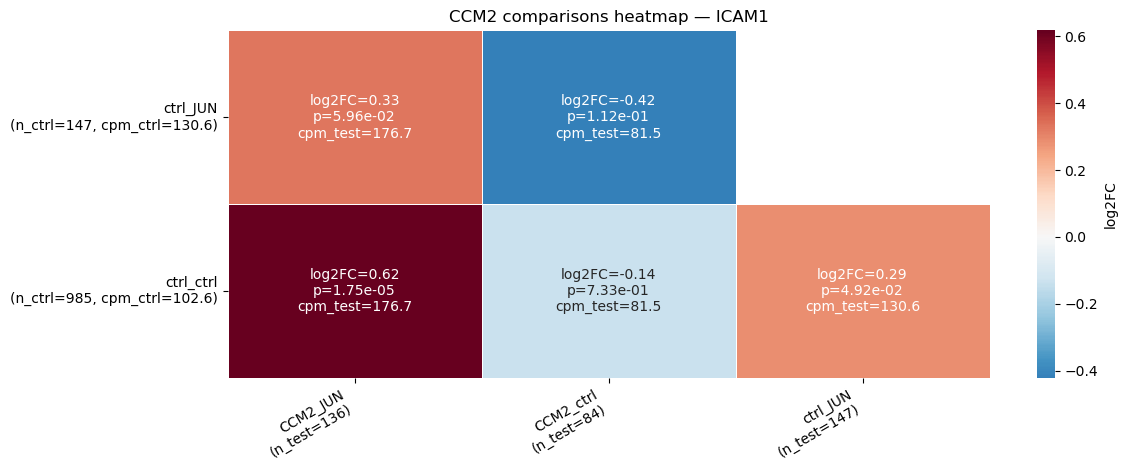

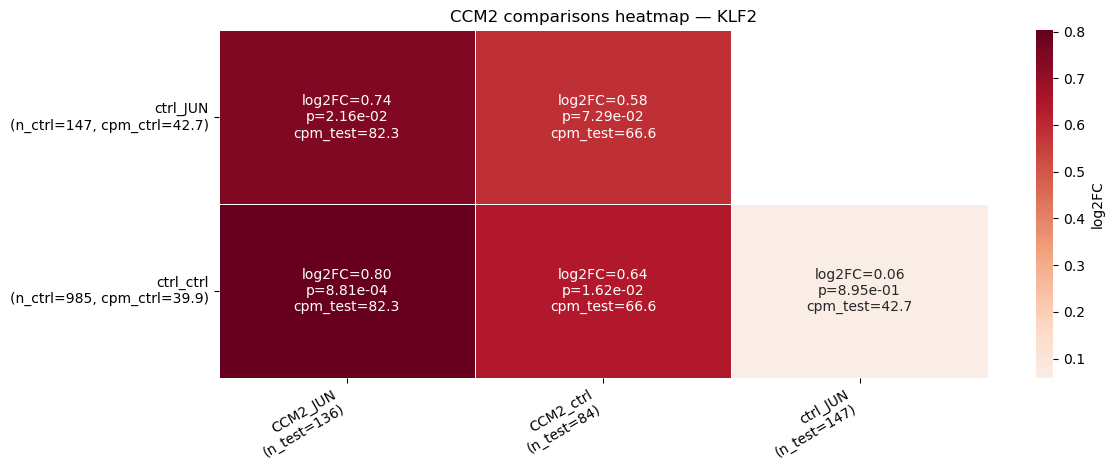

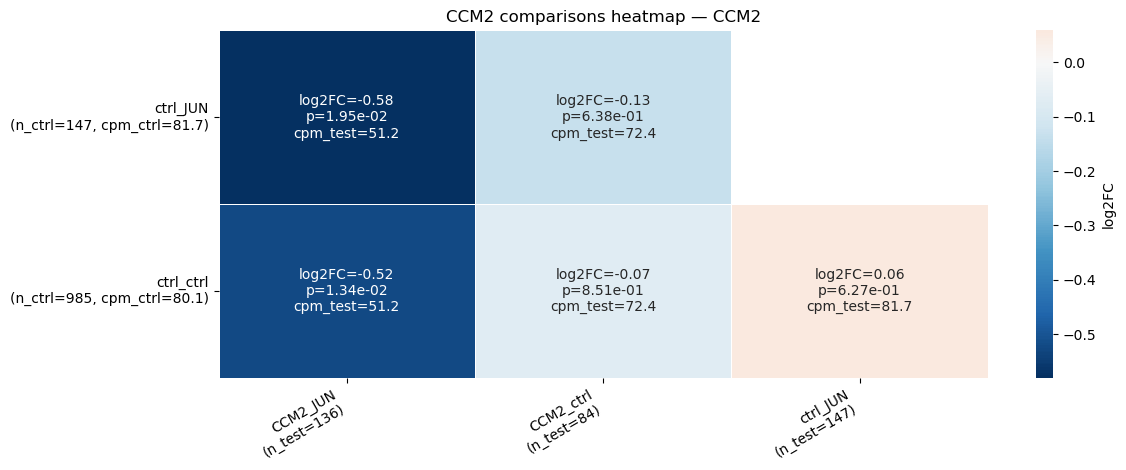

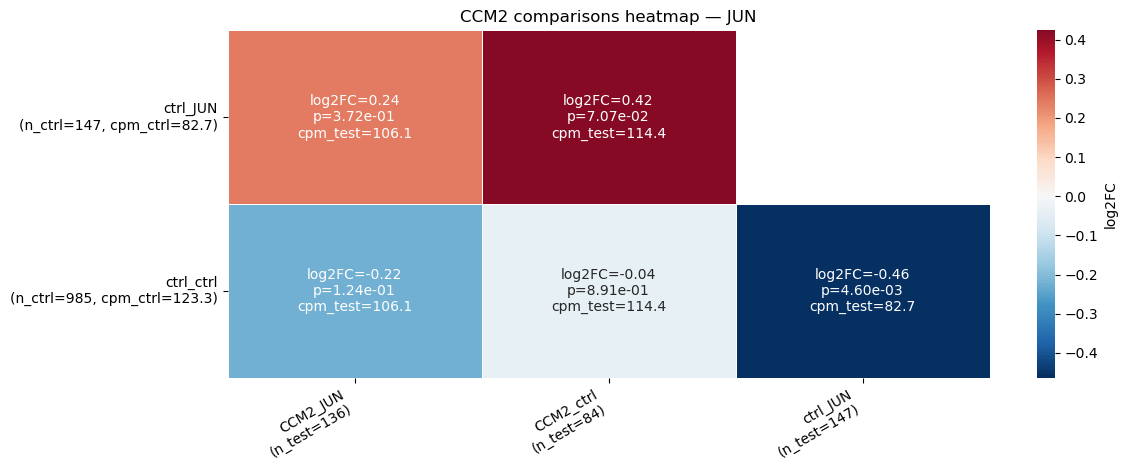

In [9]:
%matplotlib inline
# Determine readout genes to plot
if 'readout_gene' in ccm2_df.columns and ccm2_df['readout_gene'].nunique() > 1:
    readout_genes_to_plot = ccm2_df['readout_gene'].unique().tolist()
else:
    readout_genes_to_plot = [None]

for rg in readout_genes_to_plot:
    if rg is not None:
        sub_df = ccm2_df[ccm2_df['readout_gene'] == rg].copy()
        title = f"CCM2 comparisons heatmap — {rg}"
    else:
        sub_df = ccm2_df.copy()
        title = "CCM2 comparisons heatmap"

    # Pivot matrices
    heat_log2fc = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='log2FC', aggfunc='mean')
    heat_pval = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='pvalue', aggfunc='mean')
    heat_cpm_test = sub_df.pivot_table(index='ctrl_label', columns='test_label', values='cpm_test', aggfunc='mean')

    # Row/column side info
    row_info = sub_df.groupby('ctrl_label')[['n_ctrl', 'cpm_ctrl']].mean()
    col_info = sub_df.groupby('test_label')['n_test'].mean()

    # Mask: white out cells where test_label == ctrl_label
    mask = pd.DataFrame(False, index=heat_log2fc.index, columns=heat_log2fc.columns)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if r == c:
                mask.loc[r, c] = True

    # Cell annotations: log2FC + pvalue + cpm_test (blank for masked cells)
    annot = heat_log2fc.copy().astype(object)
    for r in heat_log2fc.index:
        for c in heat_log2fc.columns:
            if mask.loc[r, c] or pd.isna(heat_log2fc.loc[r, c]):
                annot.loc[r, c] = ""
            else:
                annot.loc[r, c] = (
                    f"log2FC={heat_log2fc.loc[r, c]:.2f}\n"
                    f"p={heat_pval.loc[r, c]:.2e}\n"
                    f"cpm_test={heat_cpm_test.loc[r, c]:.1f}"
                )

    # Axis labels with side metrics
    row_labels = [
        f"{r}\n(n_ctrl={int(round(row_info.loc[r, 'n_ctrl']))}, cpm_ctrl={row_info.loc[r, 'cpm_ctrl']:.1f})"
        for r in heat_log2fc.index
    ]
    col_labels = [
        f"{c}\n(n_test={int(round(col_info.loc[c]))})"
        for c in heat_log2fc.columns
    ]

    # Plot
    plt.figure(figsize=(4 * max(3, len(heat_log2fc.columns)), 1.4 * max(2, len(heat_log2fc.index)) + 2))
    ax = sns.heatmap(
        heat_log2fc,
        cmap="RdBu_r",
        center=0,
        mask=mask,
        annot=annot.values,
        fmt="",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "log2FC"}
    )

    ax.set_xticklabels(col_labels, rotation=30, ha="right")
    ax.set_yticklabels(row_labels, rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title)

    plt.tight_layout()
    plt.show()

In [47]:
results_df_TLN = []
sample_name = 'Control'
for control_combo in ['ctrl_ctrl', 'ctrl_JUN']:
    for target_combo in ['TLNRD1_ctrl', 'TLNRD1_JUN', 'ctrl_JUN']:
        if target_combo == control_combo:
            continue
        readout_genes = ['ICAM1']
        combo_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_combo'] == target_combo)
        ].index.tolist()
        ctrl_cells = obs[
            (obs['sample'] == sample_name) &
            singlet_mask &
            (obs['target_combo'] == control_combo)
        ].index.tolist()
        results_df = q3.compare_expression(
            adata, combo_cells, ctrl_cells,
            readout_genes=readout_genes,
            test_label=target_combo,
            ctrl_label=control_combo,
            plot_type='both',
            show_pval=True,
            #save_path=os.path.join(qc_out_dir, f'{target_combo}_vs_{control_combo}_{sample_name}.png'),
        )
        results_df_TLN.append(results_df)

display(pd.concat(results_df_TLN, ignore_index=True))

/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1479: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1479: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1479: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/home/unix/jjiahao/main/TIMI/CSM_ccperturbseq/scripts/qc_q3_kd_efficacy.py:1479: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated 

,readout_gene,log2FC,pvalue,cohens_d,n_test,n_ctrl,cpm_test,cpm_ctrl,test_label,ctrl_label
0,ICAM1,-0.037098,0.906847,-0.020616,164,985,95.971405,102.587227,TLNRD1_ctrl,ctrl_ctrl
1,ICAM1,0.178858,0.268637,0.104948,201,985,123.991806,102.587227,TLNRD1_JUN,ctrl_ctrl
2,ICAM1,0.286290,0.049172,0.175660,147,985,130.606644,102.587227,ctrl_JUN,ctrl_ctrl
3,ICAM1,-0.323388,0.110666,-0.194940,164,147,95.971405,130.606644,TLNRD1_ctrl,ctrl_JUN
4,ICAM1,-0.107432,0.481528,-0.065315,201,147,123.991806,130.606644,TLNRD1_JUN,ctrl_JUN


---
## Q3c: Inferred Source Classification + Source 1 DE Validation

Classify inferred singlets into Source 1 (dropout) vs Source 2 (recombinant) using noise threshold from Q2.
Then repeat DE tests on Source 1 cells to validate they show comparable KD.

In [ ]:
# --- Q3c: Classify inferred sources ---
inf_classified = q3.classify_inferred_sources(
    adata, assignment_df, umi_df,
    method='percentile', percentile=50
)

if inf_classified is not None:
    print(f"\nSource classification:")
    display(inf_classified['source'].value_counts())
    
    # Save
    inf_classified.to_csv(os.path.join(qc_out_dir, 'q3c_inferred_source_classification.csv'), index=False)

In [ ]:
# --- Q3c: Source 1 DE Validation ---
if inf_classified is not None:
    source1 = inf_classified[inf_classified['source'] == 'dropout'].copy()
    print(f"Source 1 (dropout) inferred singlets: {len(source1):,}")
    
    if not source1.empty:
        source1_results = []
        for sample_name in ['Control', 'Treatment']:
            s1_sample = source1[source1['sample'] == sample_name]
            if s1_sample.empty:
                continue
            ctrl_bcs = ctrl_bcs_per_sample.get(sample_name, [])
            if len(ctrl_bcs) < 10:
                continue
            
            guide_groups = q3.get_grna_ctrl_cells(s1_sample, group_by_gene=True)
            if not guide_groups:
                continue
            
            mdf = q3.compute_kd_metrics(adata, guide_groups, ctrl_bcs, sample_name, min_cells=5)
            if not mdf.empty:
                mdf['test_set'] = 'source1_inferred'
                source1_results.append(mdf)
        
        if source1_results:
            s1_combined = pd.concat(source1_results, ignore_index=True)
            s1_combined.to_csv(os.path.join(qc_out_dir, 'q3c_source1_inferred_efficacy.csv'), index=False)
            print(f"Source 1 DE results: {len(s1_combined)} guide-target pairs")
            
            q3.plot_heatmap(
                s1_combined,
                os.path.join(qc_out_dir, 'q3c_heatmap_source1_inferred.png'),
                title_suffix=' (Source 1 Inferred)'
            )
            display(s1_combined)

---
# Q4: Fitness Analysis

Compare guide-combo frequencies between pre-lentiviral library (from Q1) and single-cell data.

> **Prerequisite:** Run Q1 (`qc_q1_guideseq.py`) first to generate combo frequency tables.

In [ ]:
import scripts.qc_q4_fitness as q4

# Path to Q1-exported combo frequency table
# Update this path to your Q1 output
combo_freq_path = os.path.join(qc_out_dir, 'q1_combo_frequencies.csv')
assign_path = os.path.join(output_dir, 'grna_assignment', 'grna_cell_assignment.csv')

if os.path.exists(combo_freq_path):
    print("Found pre-lenti combo frequency table from Q1.")
else:
    print(f"WARNING: {combo_freq_path} not found.")
    print("Run Q1 first: python scripts/qc_q1_guideseq.py --config qc_config_guideseq.yaml")

In [ ]:
# --- Q4 Part A: Cell-level fitness ---
if os.path.exists(combo_freq_path):
    fitness_merged = q4.analyze_fitness(assign_path, combo_freq_path, qc_out_dir)
    if fitness_merged is not None:
        display(fitness_merged.head(10))

In [ ]:
# --- Q4 Parts B+C: Novel combos + fitness estimation ---
if os.path.exists(combo_freq_path):
    combo_freq_df = pd.read_csv(combo_freq_path)
    assign_df = pd.read_csv(assign_path)
    
    # Standardize columns
    if 'pos1_grna' not in combo_freq_df.columns and 'pos1' in combo_freq_df.columns:
        combo_freq_df = combo_freq_df.rename(columns={'pos1': 'pos1_grna', 'pos2': 'pos2_grna'})
    
    merged = q4.identify_novel_combos(assign_df, combo_freq_df, adata.obs, qc_out_dir)
    if not merged.empty:
        q4.estimate_fitness(merged, qc_out_dir)
        print("\nFitness analysis complete.")

---
## Summary

All QC outputs are saved to the `qc_analysis/` directory:
- `q2_*`: Background noise, recombination MLE, threshold sweep
- `q3_*`: Guide efficacy, custom combo DE, inferred source classification
- `q4_*`: Fitness analysis, novel combos

> Q1 outputs (bulk guide-seq) are generated separately via CLI.